# Module 7 — Pretrained Models and the Hugging Face Ecosystem

## Lesson 7.7 — Practical Model Selection and Integration


This note brings Module 7 together. In Notes 7.1–7.6 you learned what pretrained models are, where they live, how to choose, load and use them, how to build applications on them, and what it costs to run them. Now you'll make a real decision from start to finish, the way you would at work: a team needs a model, there are several plausible candidates, and you must recommend one, with evidence, and write down what it can't do.

The task is the running example of this module: flag negative movie reviews. We'll follow five steps, which together form a checklist you can reuse for any model decision:

1. define the requirement and select candidates;
2. inspect each candidate's documentation and licence;
3. implement them and test them on representative inputs;
4. measure quality, latency and resource use, choosing settings on validation and using the test set once;
5. decide, and document limitations and failure cases.

Along the way, one candidate will look far better than the others. Part of the lesson is finding out why.

**Key question:** *How do we choose a pretrained model for a real task, and justify that choice with evidence?*

### Learning objectives
- write a model requirement as concrete, checkable criteria;
- screen candidates on licence, training data and label scheme before measuring them;
- detect evaluation leakage from a model's own training records;
- compare candidates fairly on quality, latency and memory, and tune a setting on validation;
- make a decision by rules set in advance, and record it with its evidence and known limitations.

### Prerequisites

 this note uses everything from Notes 7.1–7.6: the fixed IMDb split (7.1), model cards and licences (7.2), critical reading of benchmarks and contamination (7.3), explicit loading (7.4), representative inputs (7.5), latency and memory (7.6), and the sign test from Module 5.

### Setup

The usual imports, seeds and device check, and the same harmless warnings as in earlier notes. The first run downloads two new models (Section 1.3 lists their sizes), so it takes a while.

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

In [1]:
import json, time, hashlib
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from datasets import load_dataset
from huggingface_hub import HfApi, ModelCard, hf_hub_download
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1 | device: cpu


## 1. Define a Requirement and Select Candidate Models

### 1.1 The requirement

A vague goal ("a good sentiment model") can't be checked. A **requirement** turns it into criteria that a measurement can pass or fail. Writing it down *before* looking at any results also protects you from choosing whichever model happens to look best and then inventing reasons afterwards. Here is ours:

In [2]:
requirement = {
    "task": "flag negative English movie reviews (positive / negative)",
    "min_val_accuracy": 0.85,                       # on our own validation reviews
    "max_p95_latency_ms": 100,                      # one review at a time, on a laptop CPU
    "max_weight_memory_mb": 600,                    # parameters x 4 bytes, float32
    "allowed_licences": ["apache-2.0", "mit", "cc-by-4.0"],   # allow commercial use
    "training_data": "documented, and not including our evaluation reviews",
}
print(json.dumps(requirement, indent=2))

{
  "task": "flag negative English movie reviews (positive / negative)",
  "min_val_accuracy": 0.85,
  "max_p95_latency_ms": 100,
  "max_weight_memory_mb": 600,
  "allowed_licences": [
    "apache-2.0",
    "mit",
    "cc-by-4.0"
  ],
  "training_data": "documented, and not including our evaluation reviews"
}


Each line comes from a real constraint:
- **Accuracy at least 0.85** on our validation reviews: the product team's minimum for the feature to be worth having.
- **p95 latency within 100 ms** for one review on a laptop CPU, because users wait for the answer (Note 7.6).
- **At most 600 MB of float32 weights,** so the model fits beside the rest of the application.
- **An allowed licence:** Apache 2.0, MIT or CC-BY 4.0, all of which permit commercial use (CC-BY requires credit to the authors).
- **Documented training data that doesn't include our evaluation reviews,** so that our measurements mean something (Note 7.3, Section 4.3).

The decision rule, also fixed in advance, is: *among candidates that pass every check, choose the one with the highest validation accuracy; then tune its settings on validation, and confirm once on test.*

### 1.2 The data

We evaluate on the fixed IMDb split from Note 7.1 (the function is copied here; the fingerprints confirm the same reviews).

In [3]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [4]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc


### 1.3 Candidates

Searching the Hub for text-classification models about sentiment (Notes 7.2 and 7.3) turns up thousands. Three kinds are worth testing, and we take one of each:
- **a general sentiment model:** the SST-2 DistilBERT we've used throughout this module;
- **a model fine-tuned on exactly our task:** a DistilBERT trained on IMDb by the TextAttack project;
- **a widely used model from another domain:** a RoBERTa model for sentiment in tweets, from Cardiff University.

In [5]:
candidates = ["distilbert/distilbert-base-uncased-finetuned-sst-2-english",
              "textattack/distilbert-base-uncased-imdb",
              "cardiffnlp/twitter-roberta-base-sentiment-latest"]
api = HfApi()
for r in candidates:
    info = api.model_info(r, files_metadata=True, revision=MODEL_REVISIONS.get(r))
    weights = [(s.rfilename, round(s.size / 1e6, 1)) for s in info.siblings if s.rfilename.endswith((".safetensors", ".bin"))]
    print(f"{r}\n   task: {info.pipeline_tag} | weight files: {weights}")

distilbert/distilbert-base-uncased-finetuned-sst-2-english
   task: text-classification | weight files: [('model.safetensors', 267.8), ('pytorch_model.bin', 267.8)]


textattack/distilbert-base-uncased-imdb
   task: text-classification | weight files: [('pytorch_model.bin', 267.8)]


cardiffnlp/twitter-roberta-base-sentiment-latest
   task: text-classification | weight files: [('pytorch_model.bin', 501.0)]


All three are tagged `text-classification`. The two DistilBERTs have weight files of 267.8 MB; the RoBERTa model's is 501.0 MB. Two of them only offer the older `pytorch_model.bin` format, not safetensors (Note 7.2), which is acceptable for well-known publishers but worth noticing.

> **Key terms**
> - **Requirement:** a set of concrete, checkable criteria a model must meet, written before any measurement.
> - **Decision rule:** the procedure, fixed in advance, for choosing among candidates that meet the requirement.
> - **Candidate:** a model shortlisted for testing.

## 2. Inspect Documentation and Licence

Before running anything, we read what each candidate says about itself.

In [6]:
cards = {r: ModelCard.load(r) for r in candidates}
for r, card in cards.items():
    cfg = AutoConfig.from_pretrained(r, revision=MODEL_REVISIONS.get(r))
    meta = card.data.to_dict()
    print(f"{r}\n   licence: {meta.get('license')} | datasets: {meta.get('datasets')} | "
          f"card length: {len(card.text)} characters | labels: {cfg.id2label}")

Repo card metadata block was not found. Setting CardData to empty.


distilbert/distilbert-base-uncased-finetuned-sst-2-english
   licence: apache-2.0 | datasets: ['sst2', 'glue'] | card length: 3990 characters | labels: {0: 'NEGATIVE', 1: 'POSITIVE'}


textattack/distilbert-base-uncased-imdb
   licence: None | datasets: None | card length: 615 characters | labels: {0: 'LABEL_0', 1: 'LABEL_1'}


cardiffnlp/twitter-roberta-base-sentiment-latest
   licence: cc-by-4.0 | datasets: ['tweet_eval'] | card length: 4216 characters | labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


The three cards differ sharply:
- **SST-2 DistilBERT:** licence `apache-2.0`, training data declared (`sst2`, `glue`), a 3990-character card, and named labels (NEGATIVE, POSITIVE).
- **TextAttack IMDb DistilBERT:** no licence (`None`), no declared datasets, a 615-character card, and unnamed labels (`LABEL_0`, `LABEL_1`), so we don't even know which output means positive.
- **Twitter RoBERTa:** licence `cc-by-4.0`, trained on `tweet_eval`, and *three* labels: negative, neutral and positive.

The TextAttack card is short enough to read in full:

In [7]:
print(cards["textattack/distilbert-base-uncased-imdb"].text.strip())

## TextAttack Model Card
This `distilbert-base-uncased` model was fine-tuned for sequence classification using TextAttack 
and the imdb dataset loaded using the `nlp` library. The model was fine-tuned 
for 5 epochs with a batch size of 16, a learning 
rate of 2e-05, and a maximum sequence length of 128. 
Since this was a classification task, the model was trained with a cross-entropy loss function. 
The best score the model achieved on this task was 0.88, as measured by the 
eval set accuracy, found after 2 epochs.

For more information, check out [TextAttack on Github](https://github.com/QData/TextAttack).


It says the model was fine-tuned on "the imdb dataset" for 5 epochs with a maximum sequence length of 128, and that its best "eval set accuracy" was 0.88. But *which* parts of IMDb? This repository also contains the training script's settings, `train_args.json`, and reading it answers the question:

In [8]:
args = json.load(open(hf_hub_download("textattack/distilbert-base-uncased-imdb", "train_args.json", revision=MODEL_REVISIONS.get("textattack/distilbert-base-uncased-imdb"))))
print({k: args[k] for k in ("dataset", "dataset_train_split", "dataset_dev_split", "max_length", "best_eval_score", "best_eval_score_epoch")})

{'dataset': 'imdb', 'dataset_train_split': 'train', 'dataset_dev_split': 'test', 'max_length': 128, 'best_eval_score': 0.88, 'best_eval_score_epoch': 2}


This settles it. The model was trained on IMDb's `train` split, all of it, and its `dev_split`, the data used to choose its best epoch, was IMDb's `test` split. That has two consequences for us:
- **Our validation set is inside its training data.** We carved validation from IMDb's training half (Note 7.1), so this model has seen every one of our validation reviews, with their labels. Its validation score will measure memory, not skill.
- **Even the test split is not perfectly clean for it.** Choosing the best of 5 epochs by test accuracy is a mild form of tuning on test, which nudges its test score upwards.

This is the contamination problem from Note 7.3, found in the model's own records. Without `train_args.json` we'd have had to guess. Many repositories don't include such records, which is itself a reason for caution.

Finally, the Twitter model's card, on its data and labels:

In [9]:
print([l.strip() for l in cards["cardiffnlp/twitter-roberta-base-sentiment-latest"].text.splitlines()
       if "tweets" in l.lower() or "->" in l][:5])

['This is a RoBERTa-base model trained on ~124M tweets from January 2018 to December 2021, and finetuned for sentiment analysis with the TweetEval benchmark.', '0 -> Negative;', '1 -> Neutral;', '2 -> Positive']


It was pretrained on about 124 million tweets and fine-tuned on the TweetEval benchmark, with labels 0 negative, 1 neutral and 2 positive. Tweets are short, informal and full of usernames and links, which is a different domain from long film reviews. And our task has no "neutral" class, so we must decide how to use its three outputs (Section 3).

> **Key terms**
> - **Label scheme:** the set of output classes and what each output position means.
> - **Training records:** files that document how a model was trained, such as arguments, logs and data splits.
> - **Evaluation leakage:** evaluation data that a model saw during training or model selection, which inflates its score.

> **Common mistake:** assuming a model with unnamed labels (`LABEL_0`, `LABEL_1`) uses the order you expect. The mapping is whatever its trainer used. Check it with inputs whose answer is obvious before trusting any accuracy number.

**Check yourself.**

1. The TextAttack model chose its best epoch using IMDb's test split. Why does that make its reported 0.88 slightly optimistic, even though it never trained on test?

<details>
<summary>Worked answer</summary>

Choosing among several checkpoints by their test accuracy means the chosen one is partly the *luckiest* on that test set. Its test score includes some of that luck, so a fresh test set would probably give a slightly lower number. The effect is small with only 5 checkpoints to choose from, but it is the same mistake as tuning settings on test, and it means no part of IMDb's official data gives a perfectly clean estimate for this model.

</details>

## 3. Implement and Test on Representative Inputs

### 3.1 Loading the candidates

We load all three with the Auto classes from Note 7.4. RoBERTa prints a LOAD REPORT with two UNEXPECTED weights, `roberta.pooler.dense.*`: a pooling layer the checkpoint contains but this classification class doesn't use. As in Note 7.1, Section 4, that is harmless.

In [10]:
models = {}
for r in candidates:
    tok = AutoTokenizer.from_pretrained(r, revision=MODEL_REVISIONS.get(r))
    mod = AutoModelForSequenceClassification.from_pretrained(r, revision=MODEL_REVISIONS.get(r)).to(device).eval()
    models[r] = (tok, mod)
    print(f"loaded {r} | {sum(p.numel() for p in mod.parameters()):,} parameters")

W1017 14:49:25.947000 79282 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 14:49:26.052000 79282 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 14:49:26.074000 79282 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 10121.53it/s]

...

loaded textattack/distilbert-base-uncased-imdb | 66,955,010 parameters


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 54429.28it/s]


[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


loaded cardiffnlp/twitter-roberta-base-sentiment-latest | 124,647,939 parameters


The two DistilBERTs have 66,955,010 parameters each; the RoBERTa model has 124,647,939.

### 3.2 Making the outputs comparable

Each candidate speaks a different label language, so we need one function that turns any of them into P(positive). First, the TextAttack model's unnamed labels. Two reviews with obvious answers tell us the mapping:

In [11]:
tok, mod = models["textattack/distilbert-base-uncased-imdb"]
clear = ["An absolute triumph. I loved every minute of it.", "Dull, predictable and far too long."]
with torch.inference_mode():
    probs = mod(**tok(clear, padding=True, return_tensors="pt").to(device)).logits.softmax(-1).cpu()
for s, p in zip(clear, probs):
    print(f"LABEL_0 {p[0]:.3f} | LABEL_1 {p[1]:.3f}  {s}")

LABEL_0 0.002 | LABEL_1 0.998  An absolute triumph. I loved every minute of it.
LABEL_0 0.998 | LABEL_1 0.002  Dull, predictable and far too long.


`LABEL_1` gets 0.998 for the glowing review and `LABEL_0` gets 0.998 for the scathing one, so `LABEL_1` is positive.

For the Twitter model, we decide before measuring to compare only its positive and negative outputs and ignore neutral: P(positive) = P(pos) / (P(pos) + P(neg)). Our task forces a choice between two answers, so the honest comparison is between those two outputs. One function now serves all three models:

In [12]:
POSITIVE = {candidates[0]: [1], candidates[1]: [1], candidates[2]: [2]}   # positive output, per model
NEGATIVE = {candidates[0]: [0], candidates[1]: [0], candidates[2]: [0]}   # neutral (cardiff index 1) is ignored

def p_positive(r, texts, max_length=256, batch_size=32):
    """P(positive) for each text, from any candidate. Sorted by length to save padding (Note 7.4)."""
    tok, mod = models[r]
    order = np.argsort([len(t) for t in texts])
    p = np.empty(len(texts))
    with torch.inference_mode():
        for i in range(0, len(texts), batch_size):
            idx = order[i:i + batch_size]
            enc = tok([texts[j] for j in idx], truncation=True, max_length=max_length,
                      padding=True, return_tensors="pt").to(device)
            pr = mod(**enc).logits.softmax(-1).cpu()
            pos, neg = pr[:, POSITIVE[r]].sum(1), pr[:, NEGATIVE[r]].sum(1)
            p[idx] = (pos / (pos + neg)).numpy()                  # positive vs. negative only
    return p

### 3.3 Representative inputs

Aggregate accuracy comes later. First, we run the inputs that matter for the feature: clear cases, the negation and lukewarm cases from Note 7.5, two inputs that aren't reviews, and the start of a real validation review.

In [13]:
representative = ["An absolute triumph. I loved every minute of it.",
                  "Dull, predictable and far too long.",
                  "the movie was not bad",
                  "The acting was superb, but the story made no sense.",
                  "It was fine, I guess.",
                  "Not as bad as the critics said, but not good either.",
                  "asdkjh qwe zzz",
                  "Please reset my password.",
                  imdb["val_eval"][0][0][:400] + " ..."]                # the start of a real review
short = ["DistilBERT SST-2", "DistilBERT IMDb", "Twitter RoBERTa"]
results = {r: p_positive(r, representative) for r in candidates}
print(f"{'P(positive)':<58}" + "".join(f"{s:>17}" for s in short))
for i, text in enumerate(representative):
    shown = text if len(text) < 55 else text[:52] + "..."
    print(f"{shown:<58}" + "".join(f"{results[r][i]:>17.3f}" for r in candidates))
print("true label of the real review:", "positive" if imdb["val_eval"][1][0] else "negative")

P(positive)                                                DistilBERT SST-2  DistilBERT IMDb  Twitter RoBERTa
An absolute triumph. I loved every minute of it.                      1.000            0.998            0.993
Dull, predictable and far too long.                                   0.000            0.002            0.009
the movie was not bad                                                 0.999            0.809            0.958
The acting was superb, but the story made no sense.                   0.001            0.006            0.069
It was fine, I guess.                                                 1.000            0.787            0.971
Not as bad as the critics said, but not good either.                  0.003            0.351            0.085
asdkjh qwe zzz                                                        0.004            0.401            0.427
Please reset my password.                                             0.011            0.641            0.386
Jean Rolli

All three get the clear cases right, and all three call "the movie was not bad" positive. The differences are in how they handle uncertainty:
- **SST-2 DistilBERT** is extreme everywhere: 1.000 for "It was fine, I guess." and 0.004 for gibberish, as we saw in Note 7.5.
- **TextAttack IMDb DistilBERT** is far more moderate on unclear inputs: 0.787 for "It was fine, I guess.", 0.351 for the "not bad, not good" sentence, and 0.401 and 0.641 for the two non-reviews. Its scores are closer to "unsure" where a person would be unsure, which is a useful property.
- **Twitter RoBERTa** sits in between, and with its neutral option ignored it is also confident on the lukewarm sentence (0.971).

On the real review (a negative one), all three are right. Representative inputs don't choose the model on their own, but they show which behaviours to watch for, and they would catch a broken label mapping immediately.

**Check yourself.**

1. Why did we decide how to treat the Twitter model's neutral output *before* measuring its accuracy?

<details>
<summary>Worked answer</summary>

Because if we chose the treatment of "neutral" after seeing the accuracies, we could pick whichever option made the model look best, which is tuning on our evaluation data. Deciding in advance, based on what the task needs (a positive-or-negative answer), keeps the measurement honest.

</details>

## 4. Measure Quality, Latency and Resource Use

### 4.1 Quality on validation

All three candidates are measured on the same 500 validation reviews, truncated to the same 256 tokens.

In [14]:
val_x, val_y = imdb["val_eval"][0][:500], imdb["val_eval"][1][:500]     # the first 500 validation reviews
val_p = {}
for r, s in zip(candidates, short):
    val_p[r] = p_positive(r, val_x)
    print(f"{s:<17} validation accuracy {((val_p[r] > 0.5) == val_y).mean():.3f}  ({len(val_y)} reviews)")

DistilBERT SST-2  validation accuracy 0.874  (500 reviews)


DistilBERT IMDb   validation accuracy 0.982  (500 reviews)


Twitter RoBERTa   validation accuracy 0.834  (500 reviews)


The SST-2 model scores 0.874 and the Twitter model 0.834. The TextAttack model scores 0.982, far ahead, and we know why: it was trained on these very reviews (Section 2). Its number is real, but it measures the wrong thing. Without having read `train_args.json`, this is exactly the result that would have won the decision.

### 4.2 Latency and memory

Next, p95 latency for single reviews on this CPU (Note 7.6), and weight memory from parameters × 4 bytes:

In [15]:
latency = {}
for r, s in zip(candidates, short):
    tok, mod = models[r]
    times = []
    with torch.inference_mode():
        mod(**tok(val_x[0], truncation=True, max_length=256, return_tensors="pt").to(device))   # warm-up
        for text in val_x[:30]:
            t0 = benchmark_clock()
            mod(**tok(text, truncation=True, max_length=256, return_tensors="pt").to(device))
            times.append((benchmark_clock() - t0) * 1000)
    latency[r] = np.percentile(times, 95)
    mem = sum(p.numel() for p in mod.parameters()) * 4 / 1e6
    print(f"{s:<17} p95 latency {latency[r]:6.1f} ms | weight memory {mem:6.1f} MB")

DistilBERT SST-2  p95 latency   30.5 ms | weight memory  267.8 MB


DistilBERT IMDb   p95 latency   26.8 ms | weight memory  267.8 MB


Twitter RoBERTa   p95 latency   58.6 ms | weight memory  498.6 MB


All three are well inside the 100 ms limit on this machine, and the two DistilBERTs are about equally fast, as expected, since they share an architecture. The larger RoBERTa model is noticeably slower and needs 498.6 MB of weights, against 267.8 MB for the DistilBERTs. All fit under 600 MB.

### 4.3 Applying the requirement

Now we apply every criterion from Section 1 to every candidate:

In [16]:
checks = {}
for r, s_ in zip(candidates, short):
    licence = cards[r].data.to_dict().get("license")
    mem = sum(p.numel() for p in models[r][1].parameters()) * 4 / 1e6
    checks[s_] = {
        "licence allowed": licence in requirement["allowed_licences"],
        "training data clean": r != candidates[1],                       # textattack trained on IMDb train (Section 2)
        "val accuracy >= 0.85": bool(((val_p[r] > 0.5) == val_y).mean() >= requirement["min_val_accuracy"]),
        "p95 latency ok": bool(latency[r] <= requirement["max_p95_latency_ms"]),
        "memory ok": bool(mem <= requirement["max_weight_memory_mb"]),
    }
for s_, c in checks.items():
    print(f"{s_:<17} " + " | ".join(f"{k}: {'yes' if v else 'NO'}" for k, v in c.items()) + f"  ->  {'PASS' if all(c.values()) else 'fail'}")

DistilBERT SST-2  licence allowed: yes | training data clean: yes | val accuracy >= 0.85: yes | p95 latency ok: yes | memory ok: yes  ->  PASS
DistilBERT IMDb   licence allowed: NO | training data clean: NO | val accuracy >= 0.85: yes | p95 latency ok: yes | memory ok: yes  ->  fail
Twitter RoBERTa   licence allowed: yes | training data clean: yes | val accuracy >= 0.85: NO | p95 latency ok: yes | memory ok: yes  ->  fail


Only the SST-2 model passes every check. The TextAttack model fails twice, on the licence and on training data that overlaps our evaluation. Either failure alone rules it out, whatever its accuracy. The Twitter model has an acceptable licence and clean data, but its 0.834 falls short of 0.85: tweets are not film reviews.

### 4.4 Tuning a setting on validation

The chosen model has one important setting, `max_length`, the truncation length. Notes 7.3 and 7.4 showed that 256 tokens cuts off many reviews. Note 7.3 couldn't separate the effect of truncation from the fact that long reviews are harder, because it compared *different* reviews. Here we run the *same* 300 validation reviews at three lengths, and use the sign test to see whether the difference is real:

> **Interpret the evidence carefully.** The documentation check rejects a known contaminated candidate. For other candidates, “no documented overlap found” is more accurate than a guarantee of clean upstream training. An absent licence field is missing evidence; inspect original publisher terms before concluding that no licence exists.

In [17]:
def sign_test(p_a, p_b, labels):
    a_right, b_right = (p_a > 0.5) == labels, (p_b > 0.5) == labels
    only_a, only_b = int((a_right & ~b_right).sum()), int((~a_right & b_right).sum())
    return only_a, only_b, (binomtest(only_a, only_a + only_b).pvalue if only_a + only_b else 1.0)

sst2 = candidates[0]
sub_x, sub_y = val_x[:300], val_y[:300]                                  # the first 300 of the 500
trunc = {256: val_p[sst2][:300]}                                         # already computed above
for L in (128, 512):
    trunc[L] = p_positive(sst2, sub_x, max_length=L)
for L in (128, 256, 512):
    print(f"max_length {L:>3}: validation accuracy {((trunc[L] > 0.5) == sub_y).mean():.3f}  ({len(sub_y)} reviews)")
a, b, p = sign_test(trunc[512], trunc[256], sub_y)
print(f"512 vs 256 on the same reviews: only 512 right {a} | only 256 right {b} | p = {p:.2f}")

max_length 128: validation accuracy 0.843  (300 reviews)
max_length 256: validation accuracy 0.873  (300 reviews)
max_length 512: validation accuracy 0.903  (300 reviews)
512 vs 256 on the same reviews: only 512 right 12 | only 256 right 3 | p = 0.04


Accuracy rises with the amount of review the model can read: 0.843 at 128 tokens, 0.873 at 256 and 0.903 at 512. Comparing 512 with 256 on the same reviews, 12 reviews are right only at 512 and 3 only at 256. That split would arise by chance with probability 0.04, so the gain from reading more is real, not noise. More tokens cost more time (Note 7.3), so we check that 512 tokens still meets the latency requirement:

In [18]:
tok, mod = models[sst2]
times = []
with torch.inference_mode():
    for text in val_x[:30]:
        t0 = benchmark_clock()
        mod(**tok(text, truncation=True, max_length=512, return_tensors="pt").to(device))
        times.append((benchmark_clock() - t0) * 1000)
p95_512 = np.percentile(times, 95)
print(f"SST-2 model at max_length 512: p95 latency {p95_512:.1f} ms | within {requirement['max_p95_latency_ms']} ms: {p95_512 <= requirement['max_p95_latency_ms']}")

SST-2 model at max_length 512: p95 latency 47.9 ms | within 100 ms: True


It does, with room to spare on this machine. So the validation evidence chooses `max_length=512`.

### 4.5 One look at the test set

The model and its setting are now fixed, so we use the test set once to confirm the result. For comparison, we also run the rejected TextAttack model on the same test reviews. Its test score is the closest we can get to a fair measure of what IMDb fine-tuning achieves.

In [19]:
test_x, test_y = imdb["test_eval"][0][:500], imdb["test_eval"][1][:500]   # the first 500 test_eval reviews
test_sst2 = p_positive(sst2, test_x, max_length=512)                     # the chosen model and setting, once
test_imdb = p_positive(candidates[1], test_x)                            # the rejected IMDb model, for comparison
print(f"chosen: SST-2 model, max_length 512 | test accuracy {((test_sst2 > 0.5) == test_y).mean():.3f} | validation accuracy {((trunc[512] > 0.5) == sub_y).mean():.3f}")
print(f"IMDb model, max_length 256          | test accuracy {((test_imdb > 0.5) == test_y).mean():.3f} | validation accuracy {((val_p[candidates[1]] > 0.5) == val_y).mean():.3f}")
a, b, p = sign_test(test_imdb, test_sst2, test_y)
print(f"test, one review = {1 / len(test_y):.1%}: only IMDb model right {a} | only SST-2 model right {b} | p = {p:.2g}")

chosen: SST-2 model, max_length 512 | test accuracy 0.888 | validation accuracy 0.903
IMDb model, max_length 256          | test accuracy 0.916 | validation accuracy 0.982
test, one review = 0.2%: only IMDb model right 36 | only SST-2 model right 22 | p = 0.087


The chosen setup scores 0.888 on 500 test reviews, a little below its 0.903 on validation. That is normal: some of a validation score's height comes from having chosen the best setting on it.

The TextAttack model falls from 0.982 on validation to 0.916 on test. Most of its apparent lead was leakage. On the same test reviews it was right on 36 that our model got wrong, and wrong on 22 that ours got right; a split like that would occur by chance with probability 0.087. So on these 500 reviews we can't be confident it's better at all, and its test score is itself a little optimistic, since it picked its best epoch on IMDb test. If it *is* better, the most likely reason is clear: it was fine-tuned on IMDb itself. That's the idea Module 8 takes up, adapting a model to your data yourself, with a licence and records you control.

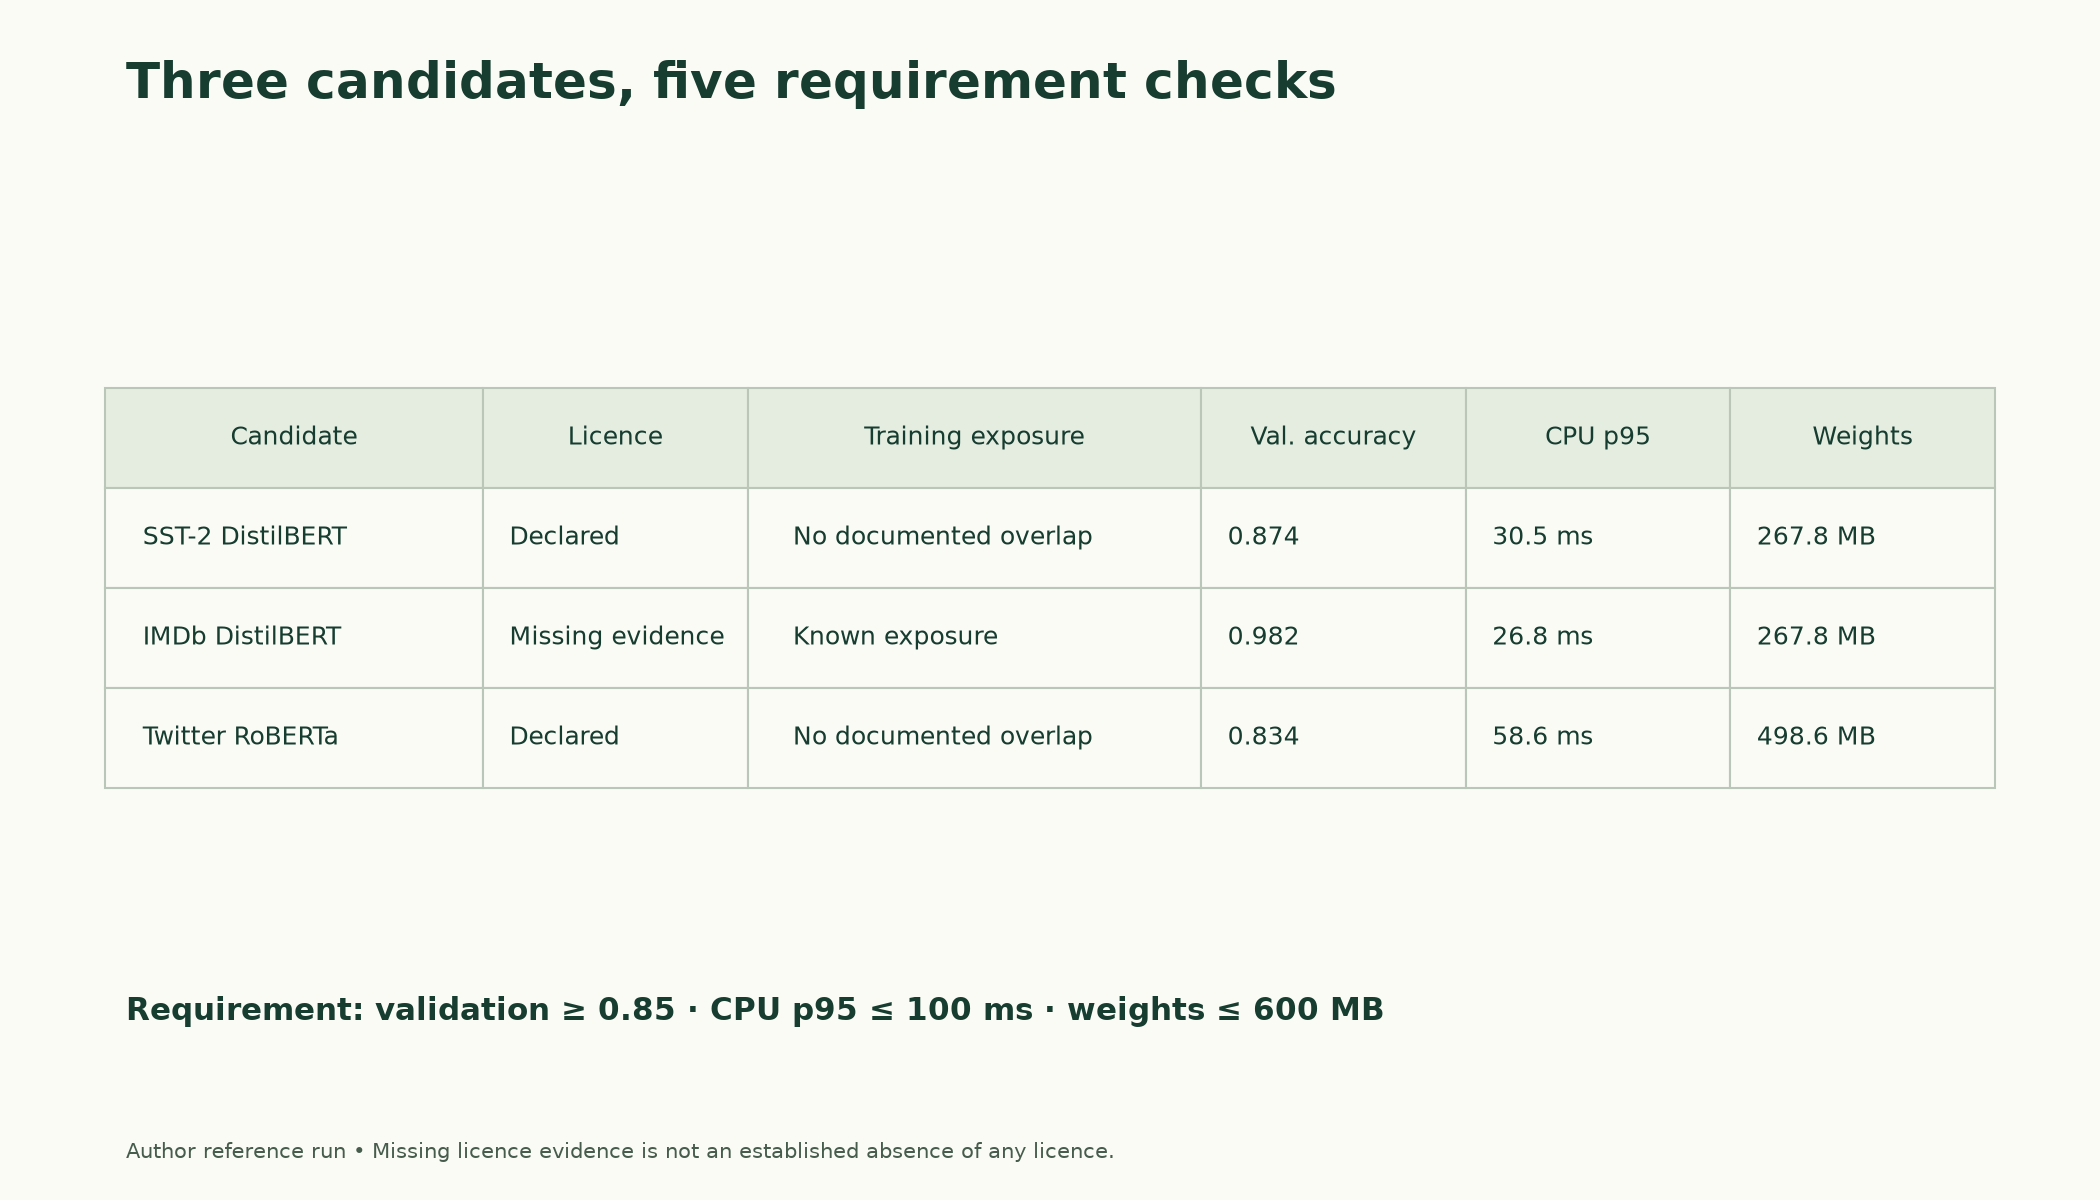

*Figure 7.7.1. Source validation and CPU measurements under declared requirements. The IMDb-trained candidate has known evaluation exposure and missing licence evidence; other candidates are screened by documented information.*

> **Key terms**
> - **Screening:** eliminating candidates on non-negotiable criteria (licence, data, size) before comparing performance.
> - **Setting (hyperparameter) tuning:** choosing values such as `max_length` by their validation results.
> - **Confirmatory test:** a single use of the test set after all choices are made, to estimate real-world performance.

> **Common mistake:** letting a spectacular number override the rules. The TextAttack model's 0.982 was the most impressive result in this note, and it was the least trustworthy. A number that looks too good is a signal to check what the model was trained on, not a reason to skip the checks.

**Check yourself.**

1. The chosen model scored 0.903 on validation and 0.888 on test. Why is it normal for the test score to be a little lower, and would it have been a problem if it had been much lower?

<details>
<summary>Worked answer</summary>

The setting (`max_length` 512) was chosen because it did best on validation, and part of that advantage is luck specific to those 300 reviews. On new reviews, that luck doesn't repeat, so a slightly lower score is expected. A *much* lower test score would be a warning: it could mean the validation set is unrepresentative, that something leaked, or that the setting was overfitted to validation, and you'd investigate before deploying.

</details>

## 5. Document Limitations and Failure Cases

### 5.1 Looking at failures

A decision isn't complete without knowing how the chosen model fails. Here are the first three validation reviews (in validation order, not chosen by outcome) that it gets wrong at the chosen setting:

In [20]:
p = trunc[512]
wrong = np.where((p > 0.5) != sub_y)[0]
print(f"SST-2 model, max_length 512: {len(wrong)} of {len(sub_y)} validation reviews wrong; the first three:")
for i in wrong[:3]:
    n = len(tok(sub_x[i], truncation=True, max_length=4096)["input_ids"])
    print(f"\n  true {'positive' if sub_y[i] else 'negative'} | P(positive) {p[i]:.3f} | {n} tokens")
    print("  " + sub_x[i][:300] + " ...")

SST-2 model, max_length 512: 29 of 300 validation reviews wrong; the first three:

  true positive | P(positive) 0.011 | 108 tokens
  Low budget Brit pop melodrama focuses on a girl who wants to be a star, becomes one and then finds it all a bit too much. Good cast and a sense of time and place cannot hide the fact that we have all been here before. Several scenes are a bit hysterical and O'Connor's voice sounds a lot like Mini Mo ...

  true negative | P(positive) 0.613 | 311 tokens
  In the autobiographical coming-of-age tale "Romulus, My Father," Eric Bana, of "Munich" fame, plays an impoverished German émigré struggling to raise his son, Raymond (Kodi Smit-McPhee), in rural 1960's Australia. The major obstacle to the family's stability and happiness is his wife, Christina (Fra ...

  true positive | P(positive) 0.003 | 132 tokens
  I think this is what this movie wants us to say at the end of the movie! or Damn Australian? I still don't know, but what I know is that I really liked 

The model gets 29 of 300 validation reviews wrong. The first three show recognisable patterns:
- **A positive review that reads like a complaint.** "Low budget Brit pop melodrama … cannot hide the fact that we have all been here before" is labelled positive, but most of its first sentences criticise the film. The model gives it 0.011.
- **A negative review that opens with neutral plot summary.** The "Romulus, My Father" review spends its opening describing the story; the model, unsure, leans positive at 0.613.
- **A review with mixed feelings.** "I really liked this movie … Great story with great actors but with a terrible end" is labelled positive, but the model fixes on the "terrible end" and gives it 0.003.

None of these is a bug. They are the hard cases of sentiment: mixed opinions, sarcasm and summary. Knowing them tells a product team what to expect, for example that mixed reviews are where human review adds most.

### 5.2 The decision record

Finally, we write the decision down, with its evidence, in a form the next person can check. It builds on the manifest from Note 7.6, extended with what was rejected and why, and with known limitations.

In [21]:
record = {
    "decision": f"use {sst2}",
    "revision": api.model_info(sst2, revision=MODEL_REVISIONS.get(sst2)).sha,
    "settings": {"max_length": 512, "label": "POSITIVE if P(positive) > 0.5"},
    "validation": {"reviews": len(sub_y), "fingerprint": fingerprint(sub_x),
                   "accuracy": round(float(((trunc[512] > 0.5) == sub_y).mean()), 3)},
    "test": {"reviews": len(test_y), "fingerprint": fingerprint(test_x),
             "accuracy": round(float(((test_sst2 > 0.5) == test_y).mean()), 3)},
    "p95_latency_on_this_machine": f"{p95_512:.1f} ms",
    "rejected": {candidates[1]: "no licence; trained on IMDb train, checkpoint chosen on IMDb test",
                 candidates[2]: "validation accuracy below 0.85; trained on tweets"},
    "known limitations": ["confident on lukewarm reviews", "confident on text that is not a review",
                          "reads only the first 512 tokens", "country bias reported in its model card (Note 7.2)"],
}
print(json.dumps(record, indent=2))

{
  "decision": "use distilbert/distilbert-base-uncased-finetuned-sst-2-english",
  "revision": "714eb0fa89d2f80546fda750413ed43d93601a13",
  "settings": {
    "max_length": 512,
    "label": "POSITIVE if P(positive) > 0.5"
  },
  "validation": {
    "reviews": 300,
    "fingerprint": "52b8a6ed1ef8",
    "accuracy": 0.903
  },
  "test": {
    "reviews": 500,
    "fingerprint": "0ff9e9d38162",
    "accuracy": 0.888
  },
  "p95_latency_on_this_machine": "47.9 ms",
  "rejected": {
    "textattack/distilbert-base-uncased-imdb": "no licence; trained on IMDb train, checkpoint chosen on IMDb test",
    "cardiffnlp/twitter-roberta-base-sentiment-latest": "validation accuracy below 0.85; trained on tweets"
  },
  "known limitations": [
    "confident on lukewarm reviews",
    "confident on text that is not a review",
    "reads only the first 512 tokens",
    "country bias reported in its model card (Note 7.2)"
  ]
}


The record pins the model to commit `714eb0fa…`, states the setting (`max_length` 512), gives the validation and test results with the fingerprints of exactly which reviews they came from, records the latency on this machine, explains why each other candidate was rejected, and lists known limitations. Those limitations come from this note and earlier ones: confidence on lukewarm reviews and on non-reviews (Note 7.5), truncation after 512 tokens (Section 4.4), and the country bias reported in the model's card (Note 7.2). If the feature misbehaves in six months, this record says where to look first, and it makes the decision easy to revisit when a better candidate appears.

> **Key terms**
> - **Failure analysis:** examining the inputs a model gets wrong to find patterns.
> - **Decision record:** a document stating what was chosen, why, on what evidence, and with which known limitations.

> **Common mistake:** recording only the winning accuracy. Without the settings, the exact data, the model commit and the reasons other candidates were rejected, nobody, including you in six months, can check or revisit the decision.

**Check yourself.**

1. Six months after deployment, a new sentiment model appears on the Hub with an Apache 2.0 licence, declared training data and a claimed accuracy of 0.95 on IMDb. Using this note's process, what would you do before replacing the current model?

<details>
<summary>Worked answer</summary>

Run it through the same process. Add it as a candidate, read its card and any training records (especially: does its training data include IMDb, and which splits?), check the licence and label mapping, test it on the same representative inputs, measure it on the same validation reviews (same fingerprint) with the same latency and memory checks, and only if it passes and wins, confirm once on the test set and update the decision record. A claimed 0.95 on IMDb is exactly the kind of number that should trigger a contamination check.

</details>

## Putting It All Together

Let's reassemble the selection, and with it Module 7.

We started from a **requirement** written before any measurement: binary sentiment of English movie reviews, validation accuracy of at least 0.85, p95 latency within 100 ms, at most 600 MB of weights, an allowed licence, and clean training data. We chose three **candidates** of three kinds: a general sentiment model, one fine-tuned on our exact task, and one from another domain.

**Reading the documentation** did half the work. The SST-2 model had an Apache 2.0 licence and declared data. The Twitter model had CC-BY 4.0 and three labels from a different domain. The TextAttack model had no licence and unnamed labels, and its `train_args.json` showed it was trained on IMDb's train split and tuned on its test split. **Representative inputs** fixed its label mapping (`LABEL_1` is positive) and revealed different behaviours on unclear inputs. **Measurement** on 500 validation reviews gave 0.874, 0.982 and 0.834. Applying the requirement left only the SST-2 model: the TextAttack model's 0.982 was leakage, and the Twitter model fell short. **Tuning** `max_length` on validation raised accuracy from 0.873 at 256 tokens to 0.903 at 512 (sign test p = 0.04), within the latency limit, and **one look at the test set** confirmed 0.888. The leaked model fell from 0.982 to 0.916 on test, and its remaining edge was not significant on 500 reviews (p = 0.087). Finally, **failure analysis** and a **decision record** captured what the model gets wrong and why it was chosen.

This is Module 7's answer to its key question, *how can AI engineers leverage models that have already learned useful representations?* Find candidates by task (7.2–7.3), load and run them correctly (7.4), wrap them in an application that handles messy inputs (7.5), fit them to deployment constraints (7.6), and choose among them with rules, fair measurement and honest records (7.7).

| Step | What we did | What it revealed |
|---|---|---|
| 1. Requirement | criteria and decision rule fixed in advance | a checklist that numbers can't override |
| 2. Documentation | cards, licences, `train_args.json` | no licence and leaked data for the TextAttack model |
| 3. Representative inputs | label mapping, edge cases | `LABEL_1` = positive; different behaviour on unclear inputs |
| 4. Measurement | validation (500), latency, memory, tuning (300), test once (500) | SST-2 model passes; 512 tokens is better; test 0.888 |
| 5. Documentation | failure analysis, decision record | mixed and summary-heavy reviews are the hard cases |

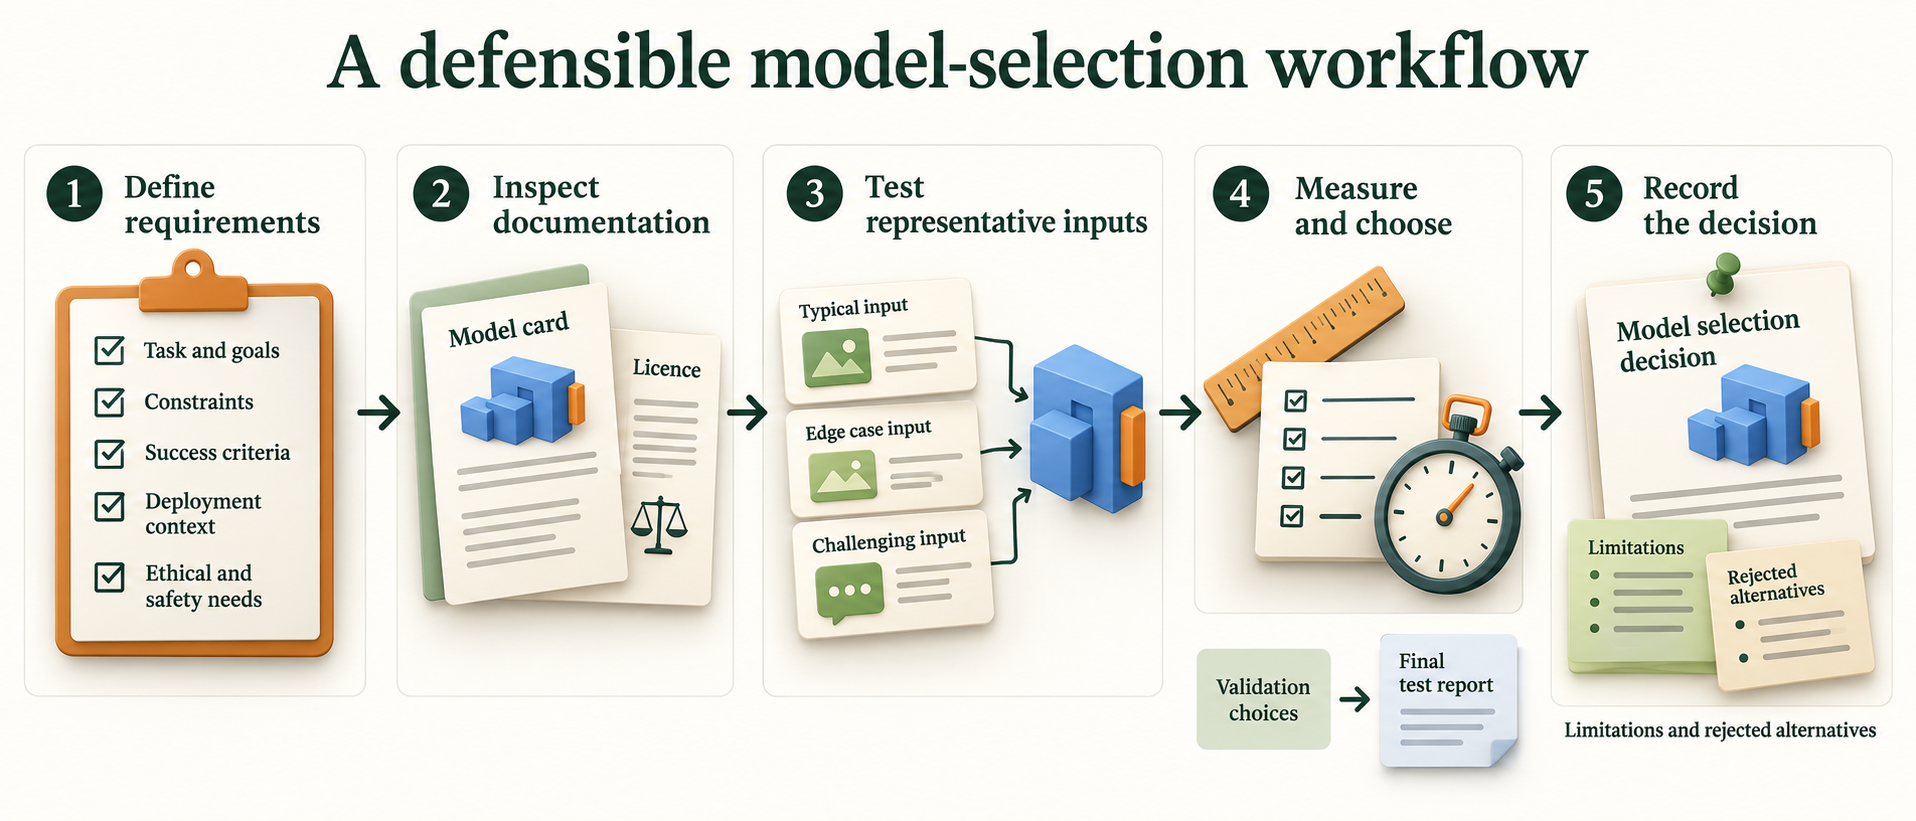

*Figure 7.7.2. Requirements, documentation, representative inputs, validation choices and final reporting belong in a recorded process. Repeated selection on a test sample requires a new final test.*

## Summary

- Start with a **requirement**: concrete criteria (accuracy, latency, memory, licence, training data) and a **decision rule**, both written before measuring.
- **Read the documentation first.** The TextAttack IMDb model had no licence, unnamed labels, and training records (`train_args.json`) showing it trained on IMDb train and chose its checkpoint on IMDb test.
- **Map every model to a common output** and check the mapping with obvious inputs: `LABEL_1` was positive; the Twitter model's neutral output was set aside by a rule fixed in advance.
- **Representative inputs** revealed different behaviours: the SST-2 model is extreme on unclear inputs, the TextAttack model more moderate.
- On 500 validation reviews: SST-2 0.874, TextAttack 0.982 (leaked), Twitter 0.834. Only the SST-2 model passed every check.
- **Tune on validation:** for the chosen model, 512 tokens beat 256 on the same 300 reviews (0.903 vs 0.873, sign test p = 0.04), within the latency limit.
- **Use the test set once:** 0.888 for the chosen setup. The leaked model dropped to 0.916, and its edge was not significant on 500 reviews (p = 0.087).
- **Document** failure cases (mixed opinions, plot summary) and a **decision record** with model commit, settings, data fingerprints, results, rejections and limitations.

## Glossary

| Term | Meaning |
|---|---|
| Requirement | Concrete, checkable criteria a model must meet, written before measuring. |
| Decision rule | The procedure, fixed in advance, for choosing among candidates. |
| Candidate | A model shortlisted for testing. |
| Label scheme | The set of output classes and what each output position means. |
| Training records | Files documenting how a model was trained: arguments, logs, data splits. |
| Evaluation leakage | Evaluation data seen during training or model selection, inflating scores. |
| Screening | Eliminating candidates on non-negotiable criteria before comparing performance. |
| Setting (hyperparameter) tuning | Choosing settings such as `max_length` by validation results. |
| Confirmatory test | A single use of the test set after all choices are made. |
| Failure analysis | Examining the inputs a model gets wrong to find patterns. |
| Decision record | A document of what was chosen, why, on what evidence, with which limitations. |